
                  📊DONE BY\JAMEEL FAIZ BOKAISH📊


                   📊SUPERVISED BY\ANAS KHODAIF📊

# About this project :
### The objective of this project is to classify whether someone has diabetes or not.
### Dataset consists of several Medical Variables(Independent) and one Outcome Variable(Dependent)

# About the Dataset
### Pregnancies : Number of times a woman has been pregnant
### Glucose : Plasma Glucose concentration of 2 hours in an oral glucose tolerance test
### BloodPressure :Diastollic Blood Pressure (mm hg)
### SkinThickness :Triceps skin fold thickness(mm)
### Insulin : 2 hour serum insulin(mu U/ml)
### BMI : Body Mass Index ((weight in kg/height in m)^2)
### Age :Age(years)
### DiabetesPedigreeFunction :scores likelihood of diabetes based on family history)
### Outcome : 0(doesn't have diabetes) or 1 (has diabetes)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
import xgboost as xgb
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
import joblib

In [2]:
# Import the files module from Google Colab
from google.colab import files

# Upload a file from your computer
uploaded = files.upload()

Saving diabetes.csv to diabetes.csv


In [3]:

# Read the uploaded CSV file
df = pd.read_csv('diabetes.csv')

# Display the first five rows
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
# Display the number of rows and columns
df.shape

(768, 9)

In [5]:
# Display information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [6]:
# Display all column names
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [7]:
# Display the statistical summary of the dataset
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [8]:
# Count missing values in each column
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [9]:
# Count the records in each Outcome class
df['Outcome'].value_counts()

,count
Outcome,
0,500
1,268


In [10]:
# Count zero values in each column
(df == 0).sum()

,0
Pregnancies,111
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,500


In [11]:
# Create a copy of the original dataset
df_clean = df.copy()

# Define columns where zero represents an invalid measurement
zero_columns = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# Replace zero values with NaN
df_clean[zero_columns] = df_clean[zero_columns].replace(0, float('nan'))

# Display the number of missing values in each column
df_clean.isnull().sum()

,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


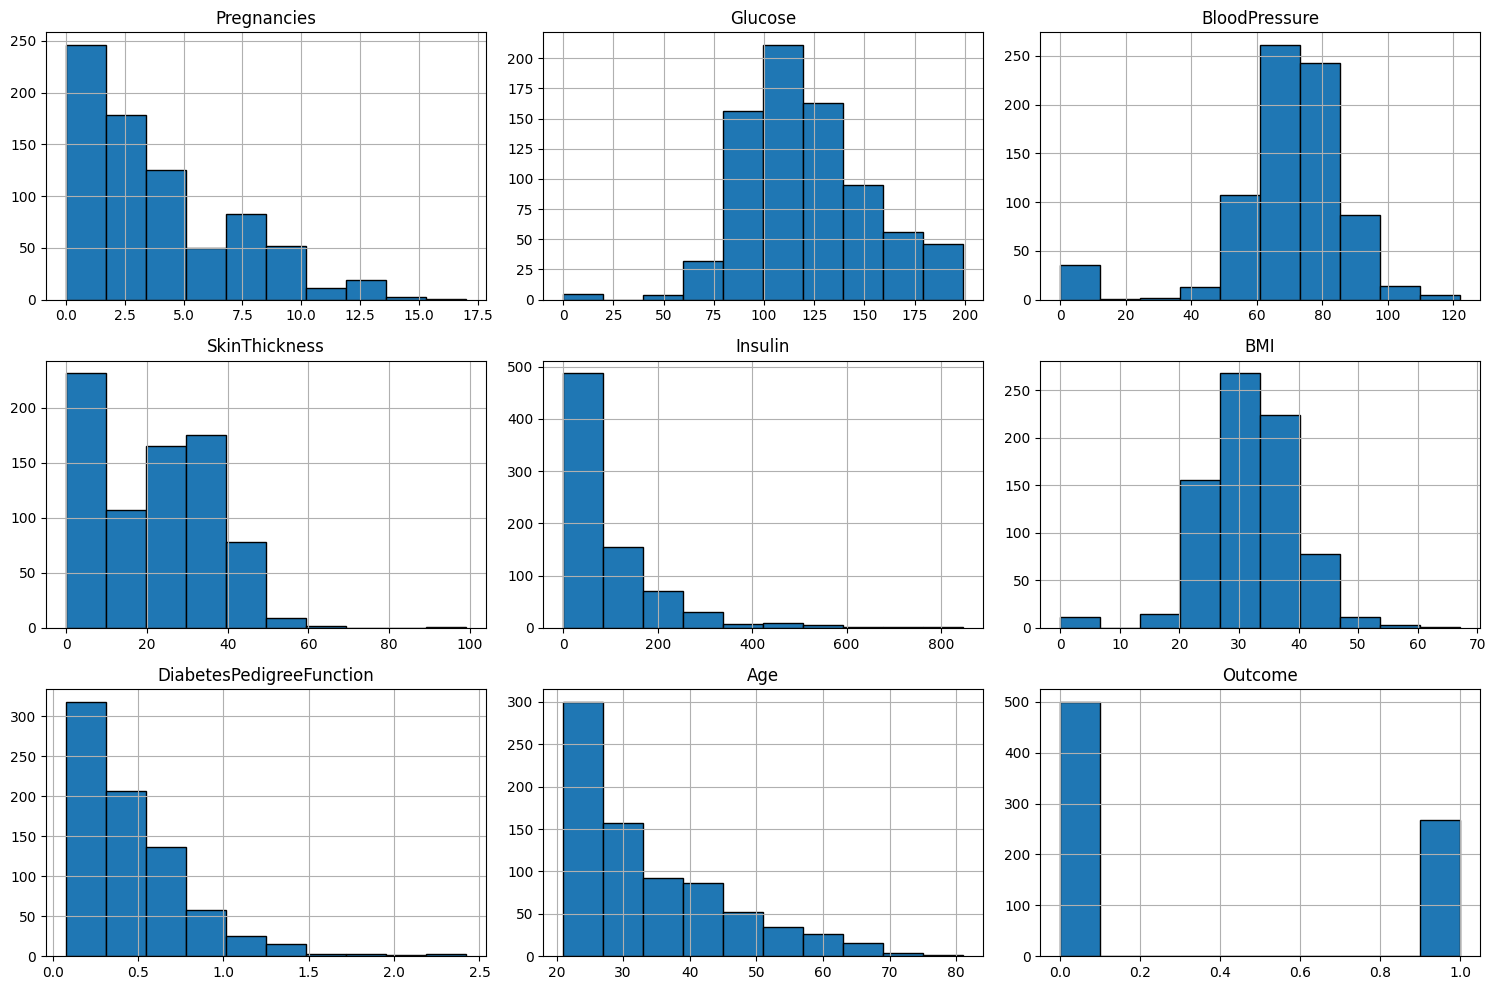

In [12]:
# Plot histograms to understand the distribution of dataset features
df.hist(bins=10, figsize=(15, 10), edgecolor='black')

# Adjust the layout
plt.tight_layout()

# Display the histograms
plt.show()

In [13]:
# Replace missing values with the median of each column
df_clean = df_clean.fillna(df_clean.median())

# Check missing values after imputation
df_clean.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [14]:
# Separate input features and target variable
X = df_clean.drop('Outcome', axis=1)
y = df_clean['Outcome']

# Display dataset information
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Total missing values:", X.isnull().sum().sum())

# Import the train_test_split function
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the dimensions of the resulting datasets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Features shape: (768, 8)
Target shape: (768,)
Total missing values: 0
Training features: (614, 8)
Testing features: (154, 8)
Training target: (614,)
Testing target: (154,)


In [15]:
# Calculate the correlation matrix
correlation_matrix = df_clean.corr()

# Display the correlation matrix
correlation_matrix

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.128213,0.208615,0.081770,0.025047,0.021559,-0.033523,0.544341,0.221898
Glucose,0.128213,1.000000,0.218937,0.192615,0.419451,0.231049,0.137327,0.266909,0.492782
BloodPressure,0.208615,0.218937,1.000000,0.191892,0.045363,0.281257,-0.002378,0.324915,0.165723
SkinThickness,0.081770,0.192615,0.191892,1.000000,0.155610,0.543205,0.102188,0.126107,0.214873
Insulin,0.025047,0.419451,0.045363,0.155610,1.000000,0.180241,0.126503,0.097101,0.203790
BMI,0.021559,0.231049,0.281257,0.543205,0.180241,1.000000,0.153438,0.025597,0.312038
DiabetesPedigreeFunction,-0.033523,0.137327,-0.002378,0.102188,0.126503,0.153438,1.000000,0.033561,0.173844
Age,0.544341,0.266909,0.324915,0.126107,0.097101,0.025597,0.033561,1.000000,0.238356
Outcome,0.221898,0.492782,0.165723,0.214873,0.203790,0.312038,0.173844,0.238356,1.000000


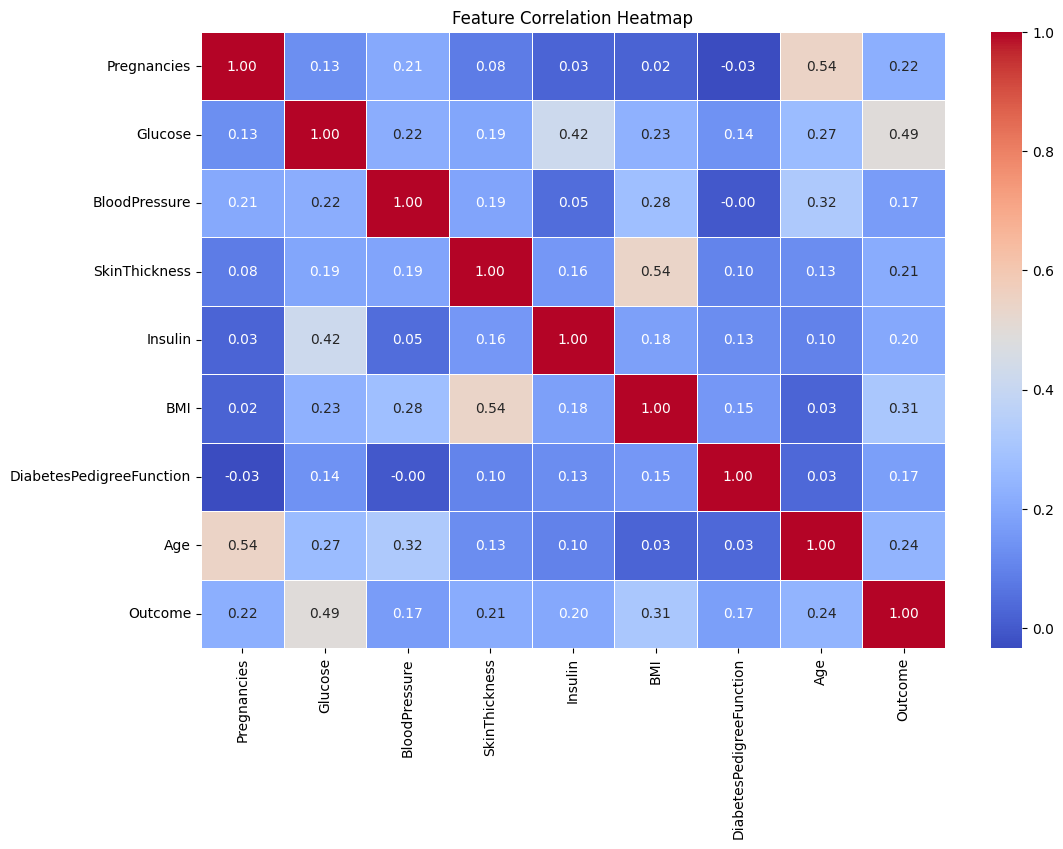

In [16]:
# Set the figure size
plt.figure(figsize=(12, 8))

# Create the correlation heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

# Add chart title
plt.title('Feature Correlation Heatmap')

# Display the chart
plt.show()

In [24]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create a scaler object
scaler = StandardScaler()

# Scale the training data
X_train_scaled = scaler.fit_transform(X_train_imputed)

# Scale the testing data
X_test_scaled = scaler.transform(X_test_imputed)

# Display the results
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (614, 8)
Testing data shape: (154, 8)


In [25]:
# Train the Logistic Regression model
lr_model = LogisticRegression(random_state=42, max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

# Generate predictions
y_pred_lr = lr_model.predict(X_test_scaled)

print("Model trained successfully!")

Model trained successfully!


In [26]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred_lr)
precision = precision_score(y_test, y_pred_lr)
recall = recall_score(y_test, y_pred_lr)
f1 = f1_score(y_test, y_pred_lr)

# Display model performance
print("Logistic Regression Performance")
print("--------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

# Display detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Performance
--------------------------------
Accuracy:  0.7078
Precision: 0.6000
Recall:    0.5000
F1-Score:  0.5455

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



In [27]:
# Import Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_imputed, y_train)

# Predict the testing data
y_pred_rf = rf_model.predict(X_test_imputed)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [28]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate Random Forest performance
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)

# Display evaluation results
print("Random Forest Performance")
print("--------------------------")
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-Score:  {rf_f1:.4f}")

Random Forest Performance
--------------------------
Accuracy:  0.7338
Precision: 0.6444
Recall:    0.5370
F1-Score:  0.5859


In [29]:
# Create a comparison table
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [accuracy, rf_accuracy],
    'Precision': [precision, rf_precision],
    'Recall': [recall, rf_recall],
    'F1-Score': [f1, rf_f1]
})

# Display model comparison
model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.7078,0.6000,0.500,0.5455
1,Random Forest,0.7338,0.6444,0.537,0.5859


In [30]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_imputed, y_train)

y_pred_xgb = xgb_model.predict(X_test_imputed)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb)
xgb_recall = recall_score(y_test, y_pred_xgb)
xgb_f1 = f1_score(y_test, y_pred_xgb)

print("XGBoost Performance")
print("-------------------")
print(f"Accuracy:  {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall:    {xgb_recall:.4f}")
print(f"F1-Score:  {xgb_f1:.4f}")


XGBoost Performance
-------------------
Accuracy:  0.7662
Precision: 0.6731
Recall:    0.6481
F1-Score:  0.6604


In [32]:
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'XGBoost'
    ],
    'Accuracy': [
        accuracy,
        rf_accuracy,
        xgb_accuracy
    ],
    'Precision': [
        precision,
        rf_precision,
        xgb_precision
    ],
    'Recall': [
        recall,
        rf_recall,
        xgb_recall
    ],
    'F1-Score': [
        f1,
        rf_f1,
        xgb_f1
    ]
})

model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.7078,0.6000,0.5000,0.5455
1,Random Forest,0.7338,0.6444,0.5370,0.5859
2,XGBoost,0.7662,0.6731,0.6481,0.6604


In [33]:
# Install LightGBM
!pip install lightgbm -q

In [34]:
from lightgbm import LGBMClassifier

lgb_model = LGBMClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    num_leaves=15,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=-1
)

lgb_model.fit(X_train_imputed, y_train)

y_pred_lgb = lgb_model.predict(X_test_imputed)

print("LightGBM model trained successfully!")

LightGBM model trained successfully!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

lgb_accuracy = accuracy_score(y_test, y_pred_lgb)
lgb_precision = precision_score(y_test, y_pred_lgb)
lgb_recall = recall_score(y_test, y_pred_lgb)
lgb_f1 = f1_score(y_test, y_pred_lgb)

print("LightGBM Performance")
print("--------------------")
print(f"Accuracy:  {lgb_accuracy:.4f}")
print(f"Precision: {lgb_precision:.4f}")
print(f"Recall:    {lgb_recall:.4f}")
print(f"F1-Score:  {lgb_f1:.4f}")

LightGBM Performance
--------------------
Accuracy:  0.7532
Precision: 0.6600
Recall:    0.6111
F1-Score:  0.6346


In [36]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from xgboost import XGBClassifier

xgb_base = XGBClassifier(
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

param_grid = {
    'n_estimators': [200, 300, 400, 500],
    'max_depth': [2, 3, 4, 5],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'min_child_weight': [1, 3, 5, 7],
    'gamma': [0, 0.1, 0.2, 0.3]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=30,
    scoring='precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train_imputed, y_train)

print("Best Cross-Validation Precision:",
      round(xgb_search.best_score_, 4))

print("Best Parameters:")
print(xgb_search.best_params_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Cross-Validation Precision: 0.7452
Best Parameters:
{'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.01, 'gamma': 0.3, 'colsample_bytree': 0.9}


In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Get the best optimized model
best_xgb_model = xgb_search.best_estimator_

# Predict on the test data
y_pred_optimized = best_xgb_model.predict(X_test_imputed)

# Calculate performance metrics
print("Optimized XGBoost Performance")
print("-----------------------------")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_optimized):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_optimized):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_optimized):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_optimized):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_optimized))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_optimized))

Optimized XGBoost Performance
-----------------------------
Accuracy:  0.7338
Precision: 0.6585
Recall:    0.5000
F1-Score:  0.5684

Confusion Matrix:
[[86 14]
 [27 27]]

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.86      0.81       100
           1       0.66      0.50      0.57        54

    accuracy                           0.73       154
   macro avg       0.71      0.68      0.69       154
weighted avg       0.73      0.73      0.72       154



In [38]:
# Get prediction probabilities from the original XGBoost model
y_prob_xgb = xgb_model.predict_proba(X_test_imputed)[:, 1]

# Display sample probabilities
probability_results = pd.DataFrame({
    'Actual Outcome': y_test.values,
    'Predicted Probability': y_prob_xgb,
    'Predicted Class': y_pred_xgb
})

probability_results.head(15)

,Actual Outcome,Predicted Probability,Predicted Class
0,0,0.781638,1
1,0,0.023732,0
2,0,0.102842,0
3,1,0.419972,0
4,0,0.009359,0
5,0,0.354166,0
6,1,0.602693,1
7,1,0.847902,1
8,0,0.055885,0
9,0,0.969449,1


In [39]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob_xgb >= threshold).astype(int)

    results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_test, y_pred_threshold),
        'Recall': recall_score(y_test, y_pred_threshold),
        'F1-Score': f1_score(y_test, y_pred_threshold)
    })

threshold_results = pd.DataFrame(results)

threshold_results.round(4)

,Threshold,Precision,Recall,F1-Score
0,0.30,0.5915,0.7778,0.6720
1,0.35,0.6061,0.7407,0.6667
2,0.40,0.6230,0.7037,0.6609
3,0.45,0.6316,0.6667,0.6486
4,0.50,0.6731,0.6481,0.6604
5,0.55,0.6800,0.6296,0.6538
6,0.60,0.7805,0.5926,0.6737
7,0.65,0.7500,0.5000,0.6000
8,0.70,0.7576,0.4630,0.5747


In [40]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Create a pipeline to prevent data leakage
xgb_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', clone(xgb_model))
])

# Generate out-of-fold probabilities
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_probabilities = cross_val_predict(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=1
)[:, 1]

# Evaluate different thresholds on training predictions
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

results = []

for threshold in thresholds:
    predictions = (oof_probabilities >= threshold).astype(int)

    results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_train, predictions),
        'Recall': recall_score(y_train, predictions),
        'F1-Score': f1_score(y_train, predictions)
    })

pd.DataFrame(results).round(4)

,Threshold,Precision,Recall,F1-Score
0,0.30,0.5919,0.7523,0.6626
1,0.35,0.6210,0.7196,0.6667
2,0.40,0.6222,0.6542,0.6378
3,0.45,0.6618,0.6402,0.6508
4,0.50,0.6579,0.5841,0.6188
5,0.55,0.6761,0.5561,0.6103
6,0.60,0.6954,0.4907,0.5753
7,0.65,0.7029,0.4533,0.5511
8,0.70,0.7302,0.4299,0.5412


In [41]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.base import clone

# Build the final pipeline
final_xgb_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', clone(xgb_model))
])

# Train using the complete training set
final_xgb_pipeline.fit(X_train, y_train)

print("Final XGBoost pipeline trained successfully!")

Final XGBoost pipeline trained successfully!


In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Get prediction probabilities
y_prob_final = final_xgb_pipeline.predict_proba(X_test)[:, 1]

# Apply the selected threshold
final_threshold = 0.35
y_pred_final = (y_prob_final >= final_threshold).astype(int)

# Calculate performance metrics
print("Final XGBoost Model Performance")
print("--------------------------------")
print(f"Threshold: {final_threshold}")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_final):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_final):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_final):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_final):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

Final XGBoost Model Performance
--------------------------------
Threshold: 0.35
Accuracy:  0.7403
Precision: 0.6061
Recall:    0.7407
F1-Score:  0.6667

Confusion Matrix:
[[74 26]
 [14 40]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.74      0.79       100
           1       0.61      0.74      0.67        54

    accuracy                           0.74       154
   macro avg       0.72      0.74      0.73       154
weighted avg       0.76      0.74      0.74       154



In [43]:
import numpy as np
from sklearn.metrics import precision_recall_curve

# Minimum acceptable recall
target_recall = 0.65

# Calculate precision, recall and thresholds
cv_precision, cv_recall, cv_thresholds = precision_recall_curve(
    y_train,
    oof_probabilities
)

# Find thresholds that satisfy the recall target
valid_indices = np.where(cv_recall[:-1] >= target_recall)[0]

# Select the threshold with the highest precision
best_index = valid_indices[
    np.argmax(cv_precision[:-1][valid_indices])
]

optimal_threshold = cv_thresholds[best_index]

print("Optimal Threshold:", round(optimal_threshold, 4))
print("Cross-Validation Precision:", round(cv_precision[best_index], 4))
print("Cross-Validation Recall:", round(cv_recall[best_index], 4))
print("Cross-Validation F1-Score:", round(
    2 * cv_precision[best_index] * cv_recall[best_index] /
    (cv_precision[best_index] + cv_recall[best_index]), 4
))


Optimal Threshold: 0.4235
Cross-Validation Precision: 0.6393
Cross-Validation Recall: 0.6542
Cross-Validation F1-Score: 0.6467


In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Apply the selected threshold
final_threshold = optimal_threshold

y_prob_final = final_xgb_pipeline.predict_proba(X_test)[:, 1]
y_pred_final = (y_prob_final >= final_threshold).astype(int)

# Evaluate final model
print("FINAL MODEL PERFORMANCE")
print("========================")
print(f"Threshold: {final_threshold:.4f}")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_final):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_final):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_final):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_final):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

FINAL MODEL PERFORMANCE
Threshold: 0.4235
Accuracy:  0.7468
Precision: 0.6271
Recall:    0.6852
F1-Score:  0.6549

Confusion Matrix:
[[78 22]
 [17 37]]

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.78      0.80       100
           1       0.63      0.69      0.65        54

    accuracy                           0.75       154
   macro avg       0.72      0.73      0.73       154
weighted avg       0.75      0.75      0.75       154



In [45]:
import joblib

# Save the complete trained pipeline
joblib.dump(
    final_xgb_pipeline,
    'diabetes_xgboost_model.pkl'
)

# Save the selected threshold
joblib.dump(
    final_threshold,
    'diabetes_threshold.pkl'
)

print("Model and threshold saved successfully!")

Model and threshold saved successfully!


In [46]:
from google.colab import files

# Download the trained XGBoost pipeline
files.download('diabetes_xgboost_model.pkl')



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:
import joblib
from google.colab import files

# Recreate the threshold file
joblib.dump(0.4235, 'diabetes_threshold.pkl')

# Download it
files.download('diabetes_threshold.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>